# Agentes y decisiones bajo incertidumbre
## Semana 11 · Procesos de decisión de Markov (MDP)

**Material de base:** *Topics in Computer Science — Agents*, PhD. Willy Ugarte Rojas,
archivo `CS-Topics-Week11-1 (2).pdf` (113 páginas físicas).

**Laboratorio en Python para Google Colab o Jupyter · 90–120 minutos · CPU.**

Resolveremos el juego del dado del PDF y una adaptación pequeña de Grid World.
Construiremos los algoritmos con funciones comentadas, sin bibliotecas especiales de agentes
ni descargas de datos. El PDF no necesita estar cargado para ejecutar este notebook.

**Pregunta central:** si una acción puede tener varios resultados, ¿cómo decide un agente
qué hacer ahora para obtener la mayor recompensa esperada a lo largo del tiempo?


## 1. Resumen del material

Un **agente** observa su entorno y elige acciones para alcanzar una meta. Puede actuar con
reglas de condición y acción, mantener un modelo interno, seguir objetivos, optimizar una
utilidad o aprender de su experiencia. El entorno puede ser observable de forma completa o
parcial, determinista o estocástico, discreto o continuo y contener uno o varios agentes.

En búsqueda determinista, una acción conduce a un sucesor conocido. En un **MDP**, una
acción conduce a una distribución de posibles sucesores. Por ello, la solución es una
**política**: una acción para cada estado posible, que permite responder a los resultados
de la incertidumbre.

| Concepto | Símbolo | Significado |
|---|---|---|
| Estado | $s\in S$ | Información suficiente para decidir |
| Acción | $a\in A(s)$ | Alternativa que el agente puede ejecutar |
| Transición | $T(s,a,s')$ | Probabilidad de llegar a $s'$ desde $s$ con $a$ |
| Recompensa | $R(s,a,s')$ | Beneficio o costo inmediato de la transición |
| Política | $\pi(s)$ | Acción elegida en cada estado |
| Descuento | $\gamma$ | Peso de las recompensas futuras |
| Valor | $V^\pi(s)$ | Retorno esperado al seguir una política desde $s$ |
| Valor de una acción | $Q^\pi(s,a)$ | Retorno esperado al tomar $a$ y después seguir $\pi$ |

La **propiedad de Markov** supone que el estado actual y la acción contienen la información
necesaria para modelar la siguiente transición y recompensa. Si falta información relevante
del pasado, habrá que ampliar la representación del estado.

El PDF distingue métodos **con modelo**, que planifican usando transiciones y recompensas,
de métodos **sin modelo**, que aprenden mediante interacción. Aquí implementamos
planificación con un modelo conocido. Simular episodios servirá para comprobar sus predicciones.


### Objetivos y recorrido

Al terminar podrás construir un MDP, evaluar una política, encontrar una política óptima e
interpretar cómo cambian las decisiones al modificar el descuento, el ruido o las recompensas.

| Parte | Actividad | Tiempo sugerido |
|---|---|---:|
| 1–2 | Conceptos y preparación | 10 min |
| 3–4 | Juego del dado, simulación y Bellman | 20 min |
| 5–6 | Grid World e iteración de valores | 25 min |
| 7 | Iteración de políticas y comparación | 15 min |
| 8–9 | Experimentos y validación por episodios | 20 min |
| 10 | Minirretos y soluciones | 20 min |

**Cómo ejecutarlo:** en Colab usa **Archivo → Subir notebook** y luego
**Entorno de ejecución → Ejecutar todas**. En Jupyter selecciona el kernel Python 3 y ejecuta
las celdas en orden. Se usan NumPy, pandas y Matplotlib, incluidos en Colab. En un entorno
local que no los tenga: `python -m pip install numpy pandas matplotlib`.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Semillas explícitas: cada experimento puede repetirse con los mismos números aleatorios.
SEMILLA = 2026
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def mostrar_tabla(tabla):
    """Muestra una tabla en Colab/Jupyter y también funciona en Python normal."""
    try:
        from IPython.display import display
        display(tabla)
    except ImportError:
        print(tabla.to_string(index=False))

print("Entorno preparado. Solo se utiliza CPU y no se descargan datos.")


Entorno preparado. Solo se utiliza CPU y no se descargan datos.


## 2. Retorno, valor y descuento

El **retorno** de un episodio es una realización aleatoria de la suma de recompensas:

$$G_0=R_1+\gamma R_2+\gamma^2R_3+\cdots.$$

El **valor** es su esperanza: $V^\pi(s)=\mathbb{E}_\pi[G_0\mid S_0=s]$.
Una trayectoria puede salir mal aunque la política sea buena en promedio.

Con $\gamma=0$ solo importa la primera recompensa. Un $\gamma$ cercano a 1 da más peso al
futuro. En MDP finitos con recompensas acotadas y $\gamma<1$, las actualizaciones de Bellman
son contractivas. Con $\gamma=1$ hacen falta condiciones adicionales; la terminación adecuada
del juego del dado permite calcular su valor sin descuento. No se debe generalizar esa
garantía a cualquier entorno que tenga estados terminales.


In [2]:
recompensas = np.array([4, 4, 4, 4], dtype=float)
filas = []
for gamma in [0.0, 0.5, 0.9, 1.0]:
    pesos = gamma ** np.arange(len(recompensas))
    filas.append({"gamma": gamma, "retorno de [4,4,4,4]": pesos @ recompensas})
mostrar_tabla(pd.DataFrame(filas))


,gamma,"retorno de [4,4,4,4]"
0,0.0,4.000
1,0.5,7.500
2,0.9,13.756
3,1.0,16.000


## 3. El juego del dado del PDF

En cada ronda puedes **salir**: recibes 10 y termina el juego. Si decides **seguir**, recibes
4 y luego se lanza un dado: con 1 o 2 el juego termina; con 3, 4, 5 o 6 hay otra ronda.
**Las recompensas ya ganadas se conservan cuando termina el juego.**

| Estado | Acción | Siguiente estado | Probabilidad | Recompensa |
|---|---|---|---:|---:|
| jugando | salir | fin | 1 | 10 |
| jugando | seguir | jugando | 2/3 | 4 |
| jugando | seguir | fin | 1/3 | 4 |

Si siempre seguimos:

$$V^{seguir}=4+\gamma\frac{2}{3}V^{seguir}
\quad\Rightarrow\quad V^{seguir}=\frac{4}{1-2\gamma/3}.$$

Sin descuento, $V^{seguir}=12$ y $V^{salir}=10$. El mayor valor esperado de seguir no garantiza
que una partida concreta dé más de 10. Comprobaremos tanto la media como esa variabilidad.


In [3]:
# Formato común del modelo:
# modelo[estado][accion] = [(probabilidad, siguiente_estado, recompensa), ...]
# Los estados terminales tienen un diccionario de acciones vacío.
dado = {
    "jugando": {
        "salir": [(1.0, "fin", 10.0)],
        "seguir": [(2/3, "jugando", 4.0), (1/3, "fin", 4.0)],
    },
    "fin": {},
}

def validar_modelo(modelo):
    """Comprueba probabilidades, recompensas y destinos de las transiciones."""
    for estado, acciones in modelo.items():
        for accion, opciones in acciones.items():
            if not opciones:
                raise ValueError(f"Sin transiciones: {estado}, {accion}")
            probabilidades = np.array([p for p, _, _ in opciones])
            if not np.all(np.isfinite(probabilidades)) or np.any(probabilidades < 0):
                raise ValueError("Probabilidades inválidas")
            if not np.isclose(probabilidades.sum(), 1.0, atol=1e-12, rtol=0):
                raise ValueError("Las probabilidades deben sumar 1")
            for _, destino, recompensa in opciones:
                if destino not in modelo or not np.isfinite(recompensa):
                    raise ValueError("Destino o recompensa inválido")
    return True

validar_modelo(dado)
print("MDP del dado válido.")


MDP del dado válido.


### Simular una trayectoria y repetir el experimento

La siguiente función recibe una política y usa las probabilidades del modelo para sortear
el siguiente estado. Acumula las recompensas descontadas. Si alcanza el límite de pasos,
marca el episodio como **truncado**, lo que permite distinguirlo de una terminación natural.


In [12]:
def simular_episodio(modelo, politica, inicio, gamma, rng, max_pasos=500):
    estado = inicio
    retorno = 0.0
    trayectoria = []
    for t in range(max_pasos):
        if not modelo[estado]:
            break
        accion = politica[estado]
        opciones = modelo[estado][accion]
        indice = rng.choice(len(opciones), p=[p for p, _, _ in opciones])
        _, siguiente, recompensa = opciones[indice]
        retorno += gamma ** t * recompensa
        trayectoria.append({"paso": t + 1, "estado": estado, "accion": accion,
                            "recompensa": recompensa, "siguiente": siguiente})
        estado = siguiente
    return {"retorno": retorno, "pasos": len(trayectoria), "terminal": estado,
            "truncado": bool(modelo[estado]), "trayectoria": trayectoria}

def evaluar_por_simulacion(modelo, politica, inicio, gamma,
                           episodios=5000, semilla=SEMILLA, max_pasos=500):
    rng = np.random.default_rng(semilla)
    filas = []
    for _ in range(episodios):
        resultado = simular_episodio(modelo, politica, inicio, gamma, rng, max_pasos)
        filas.append({k: v for k, v in resultado.items() if k != "trayectoria"})
    return pd.DataFrame(filas)

politica_seguir = {"jugando": "seguir"}
politica_salir = {"jugando": "salir"}
partida = simular_episodio(dado, politica_seguir, "jugando", 1.0,
                          np.random.default_rng(SEMILLA))
mostrar_tabla(pd.DataFrame(partida["trayectoria"]))
print("Retorno de esta partida:", partida["retorno"])


,paso,estado,accion,recompensa,siguiente
0,1,jugando,seguir,4.0,jugando
1,2,jugando,seguir,4.0,jugando
2,3,jugando,seguir,4.0,jugando
3,4,jugando,seguir,4.0,jugando
4,5,jugando,seguir,4.0,jugando
5,6,jugando,seguir,4.0,fin


Retorno de esta partida: 24.0


Siempre seguir: media simulada = 11.894; valor teórico = 12
Intervalo normal aproximado del 95% para la media: [11.624, 12.163]
Fracción de partidas con retorno < 10: 56.4%
Episodios truncados: 0


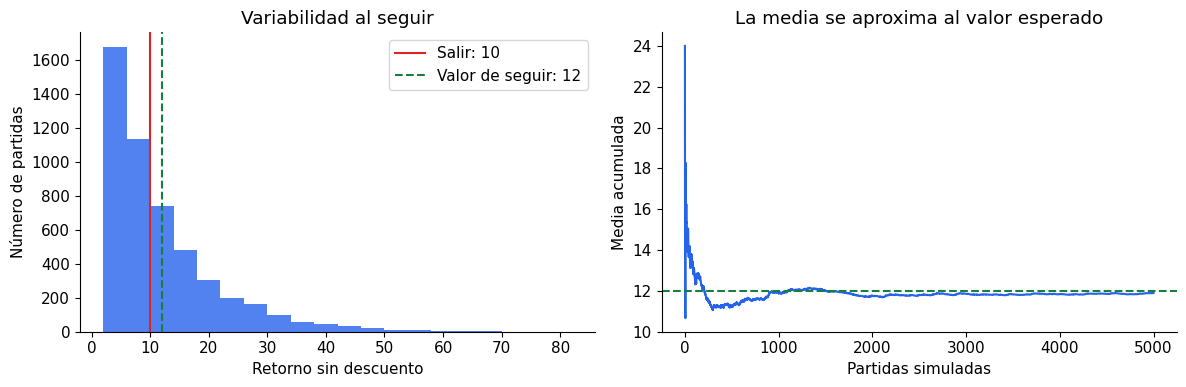

In [19]:
sim_dado = evaluar_por_simulacion(dado, politica_seguir, "jugando", 1.0)
media = sim_dado["retorno"].mean()
error_estandar = sim_dado["retorno"].std(ddof=1) / np.sqrt(len(sim_dado))
print(f"Siempre seguir: media simulada = {media:.3f}; valor teórico = 12")
print(f"Intervalo normal aproximado del 95% para la media: "
      f"[{media - 1.96 * error_estandar:.3f}, {media + 1.96 * error_estandar:.3f}]")
print(f"Fracción de partidas con retorno < 10: {(sim_dado['retorno'] < 10).mean():.1%}")
print(f"Episodios truncados: {sim_dado['truncado'].sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(sim_dado["retorno"], bins=np.arange(2, sim_dado["retorno"].max()+6, 4),
             color="#2563eb", alpha=0.8)
axes[0].axvline(10, color="#dc2626", label="Salir: 10")
axes[0].axvline(12, color="#15803d", linestyle="--", label="Valor de seguir: 12")
axes[0].set(xlabel="Retorno sin descuento", ylabel="Número de partidas",
            title="Variabilidad al seguir")
axes[0].legend()
acumulada = sim_dado["retorno"].expanding().mean()
axes[1].plot(np.arange(1, len(acumulada)+1), acumulada, color="#2563eb")
axes[1].axhline(12, color="#15803d", linestyle="--")
axes[1].set(xlabel="Partidas simuladas", ylabel="Media acumulada",
            title="La media se aproxima al valor esperado")
plt.tight_layout()
plt.show()


**Interpretación.** La media simulada debe aproximarse a 12, sin ser exactamente 12.
La probabilidad teórica de ganar menos de 10 al seguir es $1/3+(2/3)(1/3)=5/9$:
en más de la mitad de las partidas obtenemos solo 4 u 8, aunque la media sea mayor que 10.
El intervalo es una aproximación por muestreo para la **media**, no un intervalo que contenga
el 95% de las ganancias individuales.

**Pausa:** antes de continuar, predice qué política será mejor si $\gamma=0.5$.


## 4. Bellman y evaluación de una política

La evaluación mantiene una política fija y calcula:

$$Q^\pi(s,a)=\sum_{s'}T(s,a,s')\left[R(s,a,s')+\gamma V^\pi(s')\right],$$
$$V^\pi(s)=Q^\pi(s,\pi(s)).$$

Empezamos con valores cero y repetimos actualizaciones **sincrónicas**: cada nuevo vector
usa solamente el vector anterior. Detenemos el cálculo cuando el mayor cambio es pequeño.
El valor de un terminal es cero porque ya no quedan recompensas futuras; el premio se
entrega al entrar a él.


In [22]:
def valor_accion(modelo, estado, accion, valores, gamma):
    """Una actualización de Bellman para un par estado-acción."""
    return sum(p * (recompensa + gamma * valores[siguiente])
               for p, siguiente, recompensa in modelo[estado][accion])

def evaluar_politica(modelo, politica, gamma=0.9, tolerancia=1e-10, max_iter=10000):
    if not 0 <= gamma <= 1:
        raise ValueError("gamma debe estar entre 0 y 1")
    valores = {s: 0.0 for s in modelo}
    cambios = []
    activos = [s for s in modelo if modelo[s]]
    for _ in range(max_iter):
        nuevos = {s: 0.0 for s in modelo}
        for s in activos:
            nuevos[s] = valor_accion(modelo, s, politica[s], valores, gamma)
        delta = max(abs(nuevos[s] - valores[s]) for s in modelo)
        cambios.append(delta)
        valores = nuevos
        if delta < tolerancia:
            return {"valores": valores, "cambios": cambios,
                    "barridos": len(cambios), "calculos_Q": len(activos) * len(cambios)}
    raise RuntimeError("No convergió: revisa gamma, el modelo y la política")

filas = []
for gamma in [0.0, 0.5, 0.75, 0.9, 0.91, 1.0]:
    seguir = evaluar_politica(dado, politica_seguir, gamma)["valores"]["jugando"]
    salir = evaluar_politica(dado, politica_salir, gamma)["valores"]["jugando"]
    mejor = "empate" if np.isclose(seguir, salir) else ("seguir" if seguir > salir else "salir")
    filas.append({"gamma": gamma, "V(seguir)": seguir, "V(salir)": salir,
                  "mejor política": mejor})
mostrar_tabla(pd.DataFrame(filas).round(6))


,gamma,V(seguir),V(salir),mejor política
0,0.00,4.000000,10.0,salir
1,0.50,6.000000,10.0,salir
2,0.75,8.000000,10.0,salir
3,0.90,10.000000,10.0,empate
4,0.91,10.169492,10.0,seguir
5,1.00,12.000000,10.0,seguir


En este juego hay un único estado no terminal. La comparación de las dos políticas
deterministas estacionarias resuelve el problema: salir es óptimo si $\gamma<0.9$, ambas
acciones empatan si $\gamma=0.9$ y seguir es óptimo si $\gamma>0.9$.

Un descuento alto da más peso al futuro. No equivale por sí solo a una preferencia por el
riesgo; aquí el criterio es maximizar el retorno esperado.


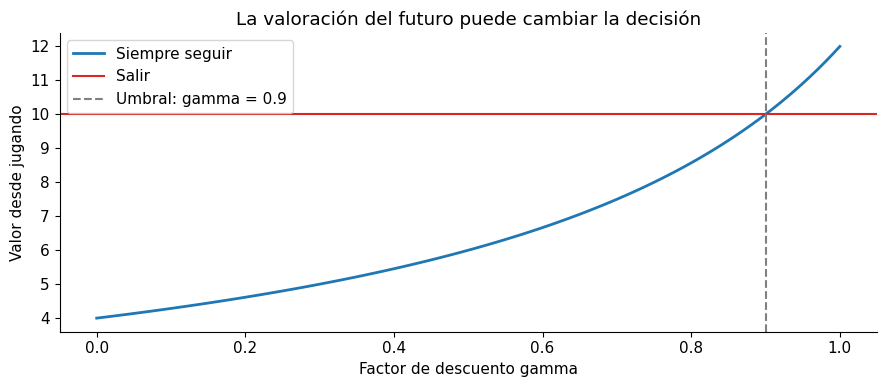

In [23]:
gammas = np.linspace(0, 1, 101)
plt.plot(gammas, 4 / (1 - 2 * gammas / 3), label="Siempre seguir", linewidth=2)
plt.axhline(10, color="#dc2626", label="Salir")
plt.axvline(0.9, color="gray", linestyle="--", label="Umbral: gamma = 0.9")
plt.xlabel("Factor de descuento gamma")
plt.ylabel("Valor desde jugando")
plt.title("La valoración del futuro puede cambiar la decisión")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Grid World: un agente que navega con incertidumbre

Usaremos una **adaptación didáctica de 3 filas por 4 columnas**, más pequeña que la cuadrícula
de 10×10 de las últimas diapositivas. No se pretende reproducir sus valores numéricos.

- Estado inicial: `(2, 0)`, esquina inferior izquierda. Las coordenadas son `(fila, columna)`
  y se cuentan desde cero; la fila 0 está arriba.
- Pared: `(1, 1)`. Terminal de éxito: `(0, 3)`, recompensa `+1`.
- Terminal de fallo: `(1, 3)`, recompensa `-1`.
- Acciones: norte, este, sur y oeste.
- Con ruido `0.2`, la dirección solicitada ocurre con probabilidad `0.8` y cada dirección
  perpendicular con `0.1`. Es el esquema 80/10/10 explicado en el PDF.
- Chocar con una pared o borde deja al agente en la misma celda.
- Cada transición que no termina recibe `-0.04`. Al entrar en un terminal se recibe
  **solamente** su premio de `+1` o `-1`; después el episodio termina.

El estado es observable, pero el resultado de una acción es aleatorio.


In [24]:
ACCIONES = ("N", "E", "S", "O")
MOVIMIENTOS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "O": (0, -1)}
FLECHAS = {"N": "↑", "E": "→", "S": "↓", "O": "←"}

def crear_grid(ruido=0.2, costo_paso=-0.04, premio=1.0, castigo=-1.0):
    if not 0 <= ruido <= 1:
        raise ValueError("El ruido debe estar entre 0 y 1")
    info = {"filas": 3, "columnas": 4, "paredes": {(1, 1)},
            "terminales": {(0, 3): premio, (1, 3): castigo}, "inicio": (2, 0)}
    estados = [(f, c) for f in range(3) for c in range(4) if (f, c) not in info["paredes"]]
    modelo = {s: {} for s in estados}
    for s in estados:
        if s in info["terminales"]:
            continue
        for i, accion in enumerate(ACCIONES):
            # Desvíos perpendiculares, a la izquierda y derecha de la dirección pedida.
            resultados = [(1 - ruido, accion), (ruido / 2, ACCIONES[(i - 1) % 4]),
                           (ruido / 2, ACCIONES[(i + 1) % 4])]
            transiciones = []
            for probabilidad, direccion in resultados:
                if probabilidad == 0:
                    continue
                df, dc = MOVIMIENTOS[direccion]
                siguiente = (s[0] + df, s[1] + dc)
                if siguiente not in modelo:
                    siguiente = s  # Borde o pared: no hay movimiento.
                recompensa = info["terminales"].get(siguiente, costo_paso)
                transiciones.append((probabilidad, siguiente, recompensa))
            modelo[s][accion] = transiciones
    validar_modelo(modelo)
    return modelo, info

grid, info = crear_grid()
mostrar_tabla(pd.DataFrame(grid[(2, 0)]["N"],
                          columns=["probabilidad", "siguiente estado", "recompensa"]))
print("Al pedir norte desde (2,0), el desvío al oeste hace que permanezcamos en (2,0).")


,probabilidad,siguiente estado,recompensa
0,0.8,"(1, 0)",-0.04
1,0.1,"(2, 0)",-0.04
2,0.1,"(2, 1)",-0.04


Al pedir norte desde (2,0), el desvío al oeste hace que permanezcamos en (2,0).


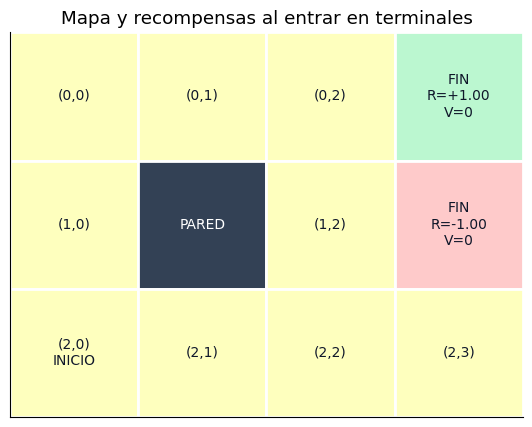

In [25]:
def dibujar_grid(info, valores=None, politica=None, titulo="Grid World", ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4.4))
    valores = valores or {}
    magnitud = max([abs(v) for v in valores.values()] + [1e-8])
    cmap = plt.get_cmap("RdYlGn")
    for f in range(info["filas"]):
        for c in range(info["columnas"]):
            s = (f, c)
            if s in info["paredes"]:
                color, texto = "#334155", "PARED"
            elif s in info["terminales"]:
                recompensa = info["terminales"][s]
                color = "#bbf7d0" if recompensa > 0 else "#fecaca"
                texto = f"FIN\nR={recompensa:+.2f}\nV=0"
            else:
                color = cmap(0.5 + 0.5 * valores.get(s, 0) / magnitud)
                flecha = FLECHAS[politica[s]] if politica and s in politica else ""
                texto = f"{flecha}\n{valores[s]:.3f}" if s in valores else f"({f},{c})"
                if s == info["inicio"]:
                    texto += "\nINICIO"
            ax.add_patch(Rectangle((c, f), 1, 1, facecolor=color,
                                   edgecolor="white", linewidth=2))
            ax.text(c+0.5, f+0.5, texto, ha="center", va="center",
                    fontsize=10, color="white" if s in info["paredes"] else "#0f172a")
    ax.set(xlim=(0, info["columnas"]), ylim=(info["filas"], 0), title=titulo)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    return ax

dibujar_grid(info, titulo="Mapa y recompensas al entrar en terminales")
plt.tight_layout()
plt.show()


## 6. Iteración de valores (Value Iteration)

Para decidir de forma óptima sustituimos la acción fija de una política por el máximo entre
las acciones disponibles:

$$V_{k+1}(s)=\max_{a\in A(s)}\sum_{s'}T(s,a,s')
\left[R(s,a,s')+\gamma V_k(s')\right].$$

Después extraemos una política con una mirada de un paso hacia adelante:

$$\pi(s)=\arg\max_a\sum_{s'}T(s,a,s')\left[R(s,a,s')+\gamma V(s')\right].$$

Guardaremos el historial para observar cómo los valores se propagan desde las recompensas.
La tolerancia controla el cambio entre iteraciones; no representa directamente el error
absoluto frente a $V^*$. Para $\gamma<1$ comprobaremos además el residuo de Bellman.


Barridos: 32
Valor desde el inicio: 0.373852


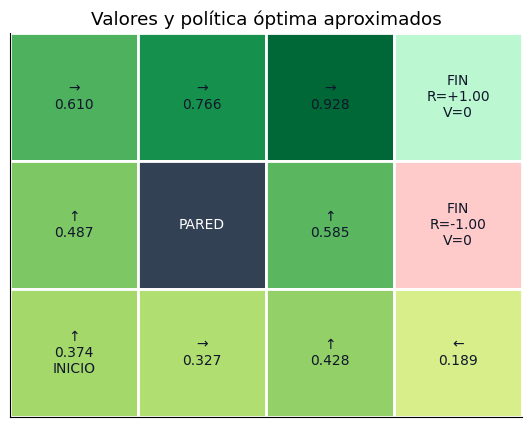

In [26]:
def extraer_politica(modelo, valores, gamma):
    return {s: max(acciones, key=lambda a: valor_accion(modelo, s, a, valores, gamma))
            for s, acciones in modelo.items() if acciones}

def iteracion_valores(modelo, gamma=0.9, tolerancia=1e-10, max_iter=10000):
    if not 0 <= gamma < 1:
        raise ValueError("En este algoritmo usamos 0 <= gamma < 1")
    valores = {s: 0.0 for s in modelo}
    historial, cambios = [valores.copy()], []
    calculos_q = 0
    for _ in range(max_iter):
        nuevos = {s: 0.0 for s in modelo}
        for s, acciones in modelo.items():
            if acciones:
                nuevos[s] = max(valor_accion(modelo, s, a, valores, gamma) for a in acciones)
                calculos_q += len(acciones)
        delta = max(abs(nuevos[s] - valores[s]) for s in modelo)
        cambios.append(delta)
        valores = nuevos
        historial.append(valores.copy())
        if delta < tolerancia:
            politica = extraer_politica(modelo, valores, gamma)
            calculos_q += sum(len(acciones) for acciones in modelo.values())
            return {"valores": valores, "politica": politica, "historial": historial,
                    "cambios": cambios, "barridos": len(cambios), "calculos_Q": calculos_q}
    raise RuntimeError("La iteración de valores no convergió")

GAMMA = 0.9
vi = iteracion_valores(grid, GAMMA)
print("Barridos:", vi["barridos"])
print(f"Valor desde el inicio: {vi['valores'][info['inicio']]:.6f}")
dibujar_grid(info, vi["valores"], vi["politica"], "Valores y política óptima aproximados")
plt.tight_layout()
plt.show()


### Un cálculo de Bellman que puedes verificar a mano

Desde `(0,2)`, pedir este puede alcanzar la meta, desviarse contra el borde o ir hacia abajo.
La tabla descompone cada contribución. La suma coincide con el valor Q de esa acción.


In [ ]:
estado, accion = (0, 2), "E"
filas = []
for p, siguiente, r in grid[estado][accion]:
    futuro = vi["valores"][siguiente]
    filas.append({"p": p, "siguiente": siguiente, "R": r, "V(siguiente)": futuro,
                  "p * (R + gamma V)": p * (r + GAMMA * futuro)})
mostrar_tabla(pd.DataFrame(filas).round(6))
print(f"Q({estado}, {accion}) = {sum(f['p * (R + gamma V)'] for f in filas):.6f}")


  p siguiente     R  V(siguiente)  p * (R + gamma V)
0.8    (0, 3)  1.00      0.000000           0.800000
0.1    (0, 2) -0.04      0.928180           0.079536
0.1    (1, 2) -0.04      0.584934           0.048644
Q((0, 2), E) = 0.928180


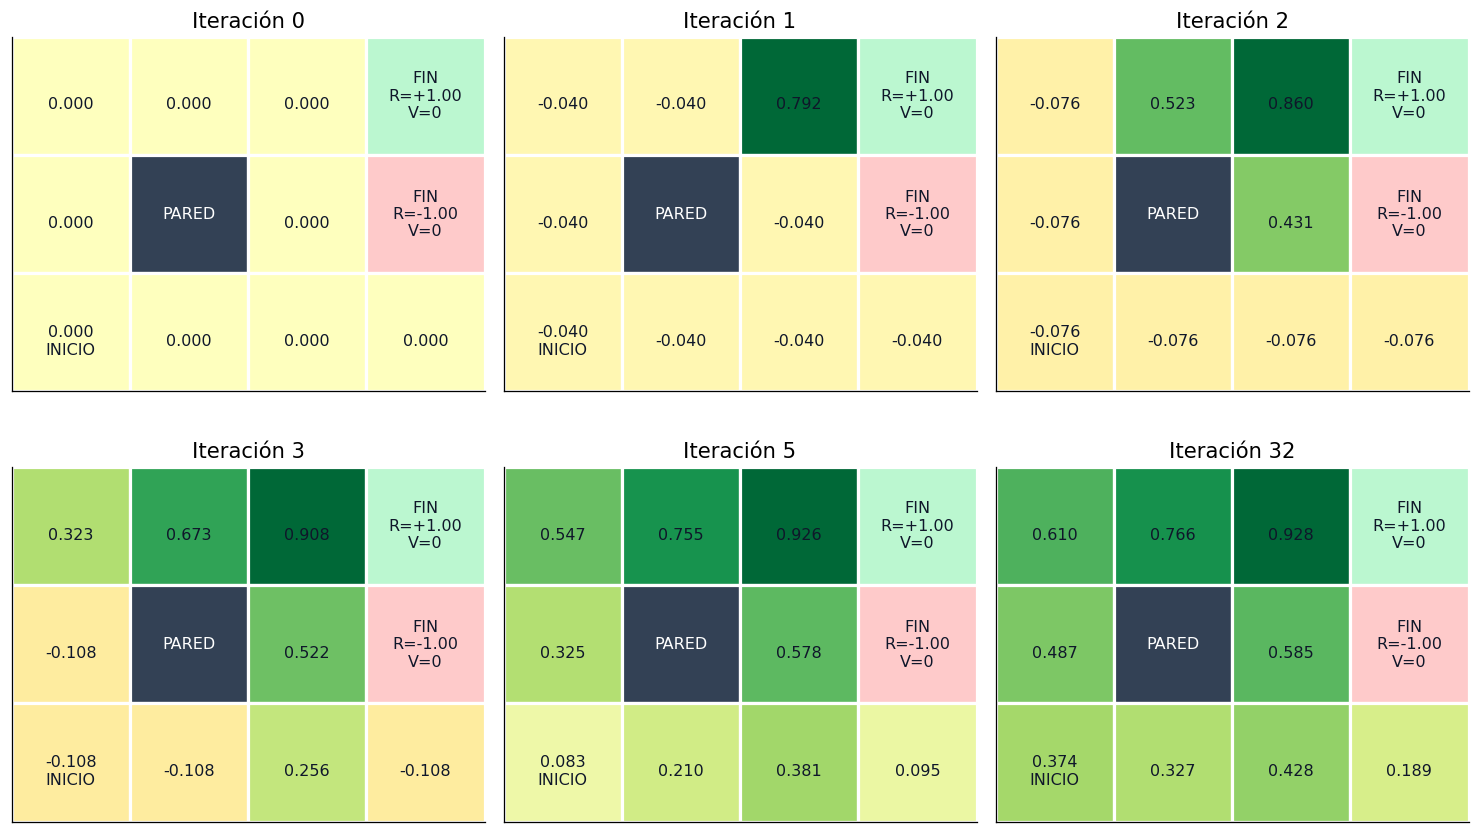

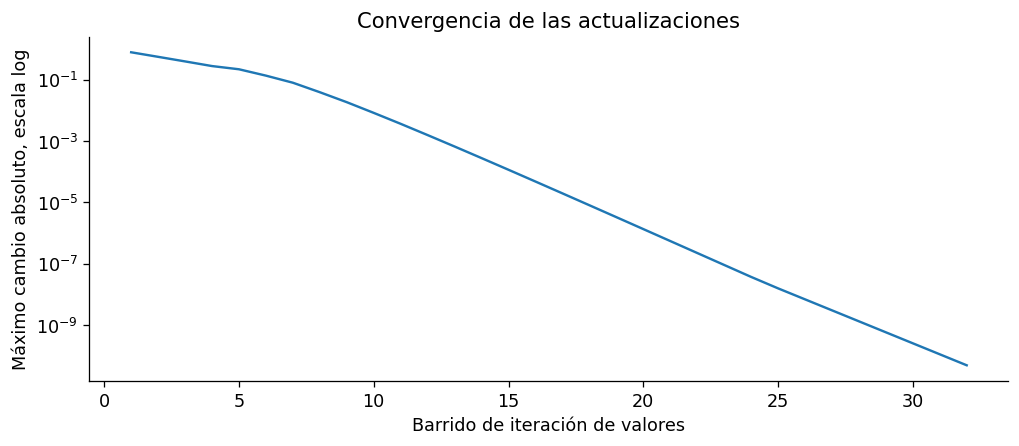

In [ ]:
indices = [0, 1, 2, 3, 5, len(vi["historial"])-1]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, k in zip(axes.flat, indices):
    vk = vi["historial"][k]
    dibujar_grid(info, vk, titulo=f"Iteración {k}", ax=ax)
plt.tight_layout()
plt.show()

plt.semilogy(np.arange(1, len(vi["cambios"])+1), np.maximum(vi["cambios"], 1e-16))
plt.xlabel("Barrido de iteración de valores")
plt.ylabel("Máximo cambio absoluto, escala log")
plt.title("Convergencia de las actualizaciones")
plt.tight_layout()
plt.show()


**Cómo leer los mapas:** las cifras de las celdas normales son retornos futuros esperados,
no recompensas inmediatas. En un terminal mostramos explícitamente su premio de entrada
y $V=0$. Sus flechas vecinas tienen en cuenta el riesgo de desvío.

En el primer barrido solo se refleja la recompensa inmediata; en los siguientes aparece el
efecto de las recompensas futuras. La intensidad del color se ajusta en cada mapa, por lo que
para comparar iteraciones utiliza las cifras.


## 7. Iteración de políticas (Policy Iteration)

1. Empezar con una política cualquiera.
2. **Evaluar:** calcular $V^\pi$ manteniendo esa política fija.
3. **Mejorar:** elegir las acciones que maximizan $Q$ usando los valores evaluados.
4. Repetir hasta que la política se mantenga estable.

En empates numéricos conservamos la acción anterior para evitar cambios innecesarios.
Evaluar cuesta varios barridos: no debemos comparar solamente el número de mejoras de
política con el número de barridos de iteración de valores.


 ronda  barridos de evaluación  acciones cambiadas
     1                     156                   6
     2                      33                   1
     3                      32                   0


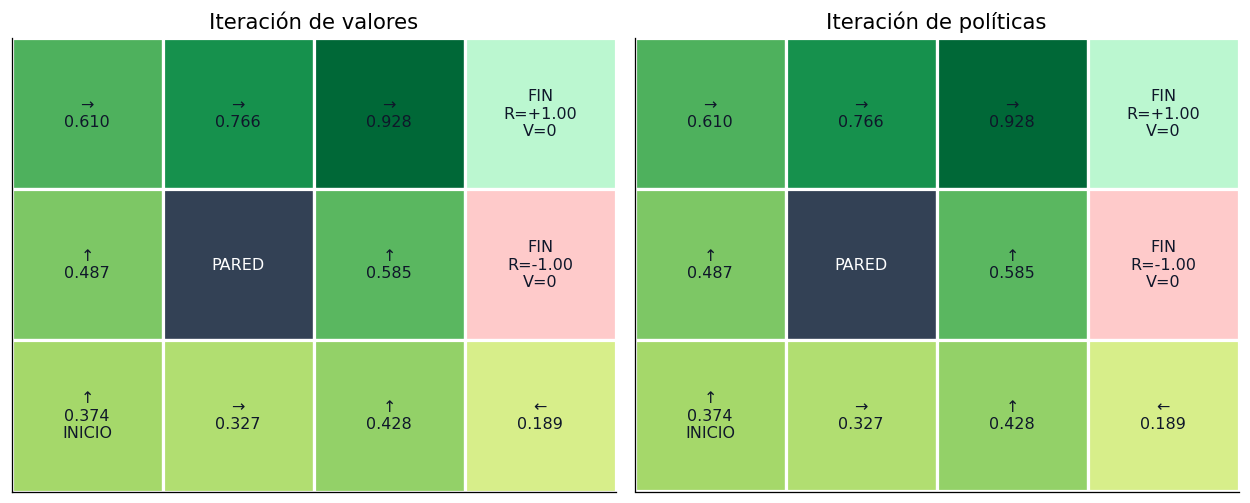

In [ ]:
def iteracion_politicas(modelo, gamma=0.9, tolerancia=1e-10, max_mejoras=100):
    if not 0 <= gamma < 1:
        raise ValueError("En este algoritmo usamos 0 <= gamma < 1")
    politica = {s: next(iter(acciones)) for s, acciones in modelo.items() if acciones}
    registro, historial = [], []
    total_q = 0
    for paso in range(1, max_mejoras+1):
        evaluacion = evaluar_politica(modelo, politica, gamma, tolerancia)
        valores = evaluacion["valores"]
        total_q += evaluacion["calculos_Q"]
        nueva = politica.copy()
        for s in politica:
            qs = {a: valor_accion(modelo, s, a, valores, gamma) for a in modelo[s]}
            total_q += len(qs)
            mejor = max(qs, key=qs.get)
            if qs[mejor] > qs[politica[s]] + 1e-10:
                nueva[s] = mejor
        cambios = sum(nueva[s] != politica[s] for s in politica)
        registro.append({"ronda": paso, "barridos de evaluación": evaluacion["barridos"],
                         "acciones cambiadas": cambios})
        historial.append({"politica": politica.copy(), "valores": valores.copy()})
        if cambios == 0:
            return {"valores": valores, "politica": politica, "registro": registro,
                    "historial": historial, "calculos_Q": total_q}
        politica = nueva
    raise RuntimeError("La iteración de políticas no se estabilizó")

pi = iteracion_politicas(grid, GAMMA)
mostrar_tabla(pd.DataFrame(pi["registro"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
dibujar_grid(info, vi["valores"], vi["politica"], "Iteración de valores", axes[0])
dibujar_grid(info, pi["valores"], pi["politica"], "Iteración de políticas", axes[1])
plt.tight_layout()
plt.show()


In [ ]:
comparacion = pd.DataFrame([
    {"algoritmo": "Iteración de valores", "barridos con máximo": vi["barridos"],
     "barridos de evaluación": 0, "rondas de mejora": 0, "cálculos Q": vi["calculos_Q"],
     "V(inicio)": vi["valores"][info["inicio"]]},
    {"algoritmo": "Iteración de políticas", "barridos con máximo": 0,
     "barridos de evaluación": sum(r["barridos de evaluación"] for r in pi["registro"]),
     "rondas de mejora": len(pi["registro"]), "cálculos Q": pi["calculos_Q"],
     "V(inicio)": pi["valores"][info["inicio"]]},
])
mostrar_tabla(comparacion.round(8))
diferencia = max(abs(vi["valores"][s] - pi["valores"][s]) for s in grid)
print(f"Diferencia máxima entre valores: {diferencia:.3e}")
print("Cálculos Q cuenta sumas sobre sucesores; no es una medición de tiempo de ejecución.")


             algoritmo  barridos con máximo  barridos de evaluación  rondas de mejora  cálculos Q  V(inicio)
  Iteración de valores                   32                       0                 0        1188   0.373852
Iteración de políticas                    0                     221                 3        2097   0.373852
Diferencia máxima entre valores: 5.273e-12
Cálculos Q cuenta sumas sobre sucesores; no es una medición de tiempo de ejecución.


Los dos métodos deben producir valores casi iguales. En problemas con empates pueden dar
políticas distintas con el mismo valor. El número de cálculos Q depende de la inicialización,
la tolerancia y la forma de evaluar la política; una tabla de este entorno pequeño no permite
afirmar que un algoritmo siempre es más rápido.

Con $S$ estados, $A$ acciones y hasta $K$ sucesores por acción, un barrido de iteración de
valores cuesta $O(SAK)$. Si se usa una representación densa con $K=S$, se obtiene el
$O(S^2A)$ del PDF. Un barrido de evaluación de una política cuesta $O(SK)$.


## 8. Experimentos: descuento, ruido y costo por paso

En cada comparación variamos un factor y mantenemos los demás fijos. Los valores de
entornos con recompensas o descuentos diferentes responden a objetivos diferentes;
para comparar políticas dentro de un mismo entorno, hay que evaluarlas con el mismo modelo.


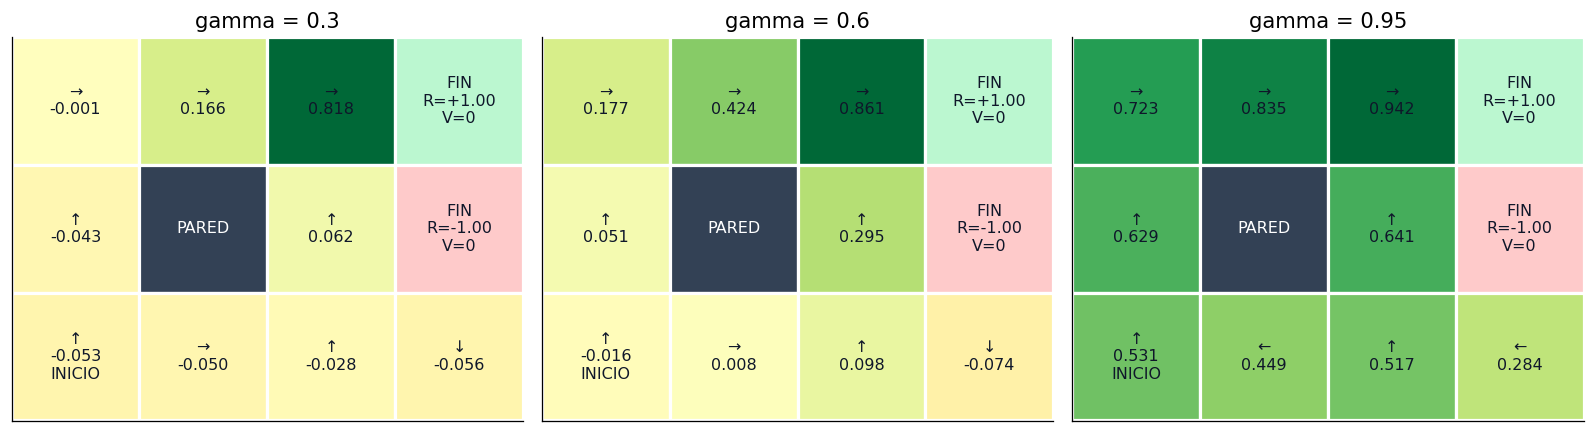

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, gamma in zip(axes, [0.3, 0.6, 0.95]):
    resultado = iteracion_valores(grid, gamma)
    dibujar_grid(info, resultado["valores"], resultado["politica"], f"gamma = {gamma}", ax)
plt.tight_layout()
plt.show()


 ruido  V(inicio) primera acción
   0.0   0.518540              N
   0.2   0.373852              N
   0.4   0.142515              N


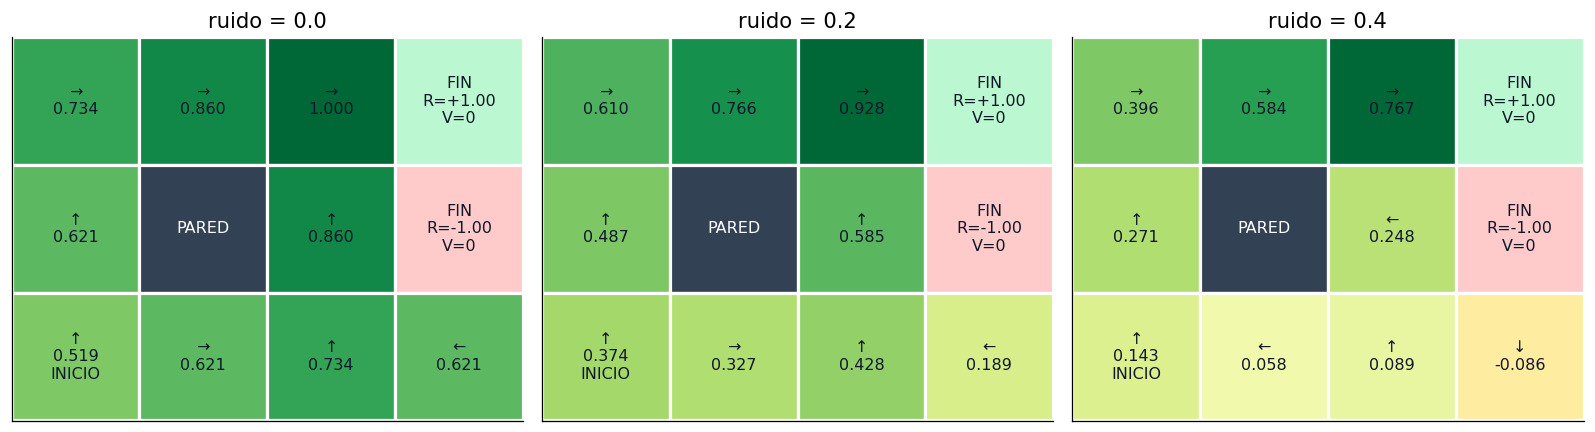

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
resumen_ruido = []
for ax, ruido in zip(axes, [0.0, 0.2, 0.4]):
    modelo_r, info_r = crear_grid(ruido=ruido)
    resultado = iteracion_valores(modelo_r, GAMMA)
    dibujar_grid(info_r, resultado["valores"], resultado["politica"], f"ruido = {ruido}", ax)
    resumen_ruido.append({"ruido": ruido, "V(inicio)": resultado["valores"][info_r["inicio"]],
                          "primera acción": resultado["politica"][info_r["inicio"]]})
plt.tight_layout()
plt.show()
mostrar_tabla(pd.DataFrame(resumen_ruido).round(6))


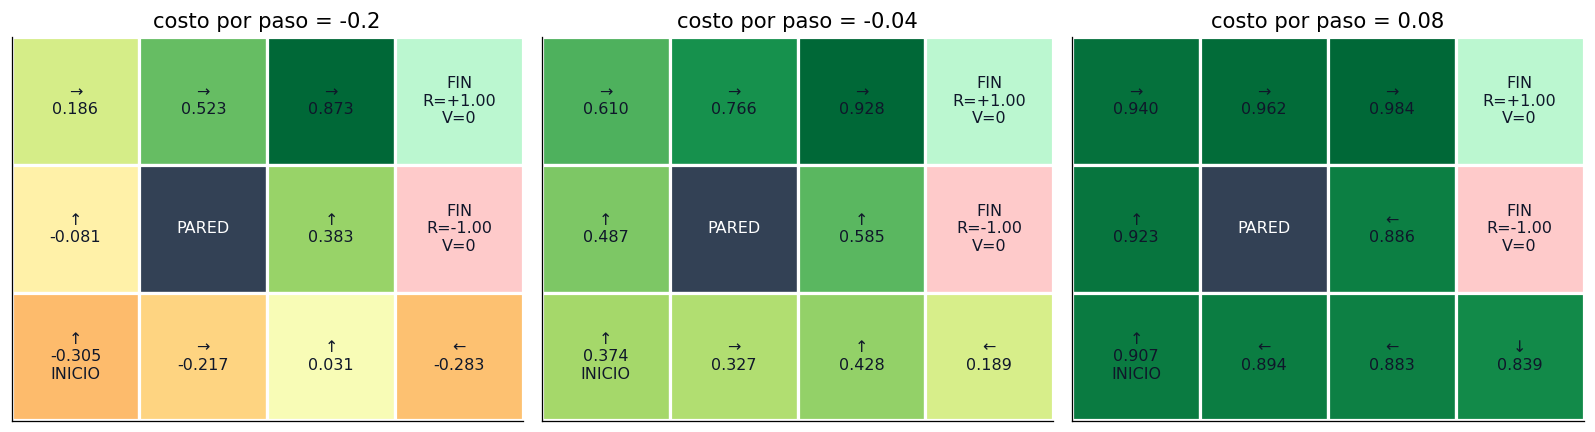

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, costo in zip(axes, [-0.2, -0.04, 0.08]):
    modelo_c, info_c = crear_grid(costo_paso=costo)
    resultado = iteracion_valores(modelo_c, GAMMA)
    dibujar_grid(info_c, resultado["valores"], resultado["politica"], f"costo por paso = {costo}", ax)
plt.tight_layout()
plt.show()


**Preguntas de interpretación:**

1. ¿Qué valores cambian más cuando aumenta $\gamma$? ¿Cambian necesariamente todas las flechas?
2. ¿Qué decisiones cerca del terminal negativo se ven afectadas por el ruido?
3. ¿Por qué pagar una recompensa positiva por cada paso puede hacer atractivo permanecer
   dando vueltas? ¿Coincide ese comportamiento con la intención de alcanzar la meta?

El algoritmo optimiza la recompensa que definimos. Una recompensa mal diseñada puede
favorecer comportamientos que no representan el objetivo deseado.


### Tu propio experimento

Modifica estas variables y vuelve a ejecutar esta celda. Después ejecuta las celdas de la
sección 9 para medir el comportamiento de la política que acabas de obtener.
Mantén `gamma < 1` para conservar la garantía de convergencia usada aquí.


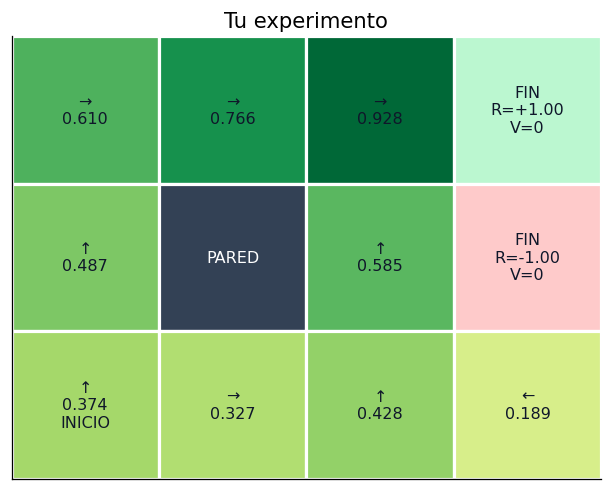

In [ ]:
# EDITA ESTOS PARÁMETROS.
MI_GAMMA = 0.9
MI_RUIDO = 0.2
MI_COSTO = -0.04
MI_PREMIO = 1.0
MI_CASTIGO = -1.0

mi_grid, mi_info = crear_grid(MI_RUIDO, MI_COSTO, MI_PREMIO, MI_CASTIGO)
mi_resultado = iteracion_valores(mi_grid, MI_GAMMA)
dibujar_grid(mi_info, mi_resultado["valores"], mi_resultado["politica"], "Tu experimento")
plt.tight_layout()
plt.show()


## 9. Validar con episodios: predicción frente a experiencia

El modelo nos permite predecir $V^\pi$. La simulación permite estimarlo por muestreo.
Comparamos la política obtenida por Bellman con una regla sencilla: **avanzar al este cuando
no hay una pared; si el este está bloqueado o en el borde, ir al norte**.

La regla es un ejemplo de agente reactivo. Su desempeño es un punto de comparación, no una
conclusión general sobre todos los agentes reactivos.

Para cada política calculamos retorno, éxito, fallo y truncamiento. Los episodios truncados
se conservan en las estadísticas; descartarlos sesgaría la comparación.


In [ ]:
politica_reactiva = {}
for s, acciones in mi_grid.items():
    if acciones:
        este = (s[0], s[1]+1)
        politica_reactiva[s] = "E" if este in mi_grid else "N"

def resumir_simulacion(nombre, simulacion, valor_modelo, info_local):
    retornos = simulacion["retorno"]
    ee = retornos.std(ddof=1) / np.sqrt(len(retornos))
    llego_meta = simulacion["terminal"].map(lambda s: s == (0, 3))
    llego_fallo = simulacion["terminal"].map(lambda s: s == (1, 3))
    return {"política": nombre, "V modelo": valor_modelo,
            "retorno medio": retornos.mean(), "error estándar": ee,
            "éxito %": 100*llego_meta.mean(), "fallo %": 100*llego_fallo.mean(),
            "truncados %": 100*simulacion["truncado"].mean(),
            "pasos medios": simulacion["pasos"].mean()}

simulaciones = {}
filas = []
for nombre, politica in [("Bellman", mi_resultado["politica"]), ("Reactiva", politica_reactiva)]:
    simulacion = evaluar_por_simulacion(mi_grid, politica, mi_info["inicio"], MI_GAMMA,
                                       episodios=5000, semilla=SEMILLA, max_pasos=500)
    simulaciones[nombre] = simulacion
    v_modelo = evaluar_politica(mi_grid, politica, MI_GAMMA)["valores"][mi_info["inicio"]]
    filas.append(resumir_simulacion(nombre, simulacion, v_modelo, mi_info))
mostrar_tabla(pd.DataFrame(filas).round(4))

# Para recompensas acotadas por R_max y gamma < 1, esta es una cota del retorno
# descontado que se omite después del límite de pasos, incluso si hay bucles.
r_max = max(abs(r) for acciones in mi_grid.values() for opciones in acciones.values()
            for _, _, r in opciones)
cota_cola = r_max * MI_GAMMA**500 / (1-MI_GAMMA)
print(f"Cota absoluta de la cola omitida a 500 pasos: {cota_cola:.3e}")
print("Si eliges un gamma muy cercano a 1, revisa la cota y aumenta max_pasos si hace falta.")


política  V modelo  retorno medio  error estándar  éxito %  fallo %  truncados %  pasos medios
 Bellman    0.3739         0.3754          0.0031    97.34     2.66          0.0        6.3566
Reactiva   -0.6671        -0.6760          0.0053    10.30    89.70          0.0        4.9958
Cota absoluta de la cola omitida a 500 pasos: 1.322e-22
Si eliges un gamma muy cercano a 1, revisa la cota y aumenta max_pasos si hace falta.


 paso estado accion  recompensa siguiente
    1 (2, 0)      N       -0.04    (1, 0)
    2 (1, 0)      N       -0.04    (0, 0)
    3 (0, 0)      E       -0.04    (0, 1)
    4 (0, 1)      E       -0.04    (0, 2)
    5 (0, 2)      E        1.00    (0, 3)
Retorno: 0.5185; pasos: 5; truncado: False


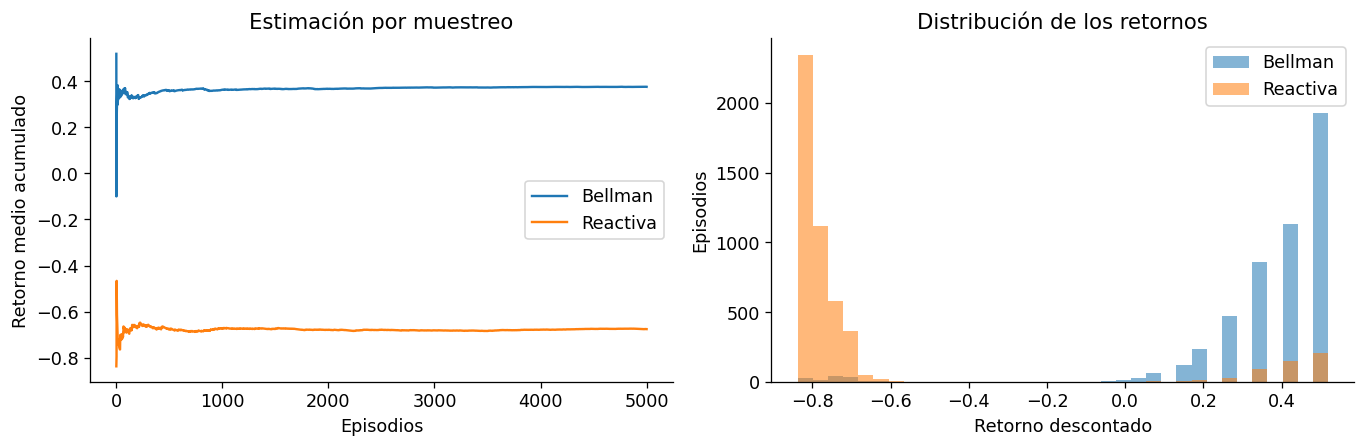

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nombre, sim in simulaciones.items():
    media_acum = sim["retorno"].expanding().mean()
    axes[0].plot(np.arange(1, len(sim)+1), media_acum, label=nombre)
    axes[1].hist(sim["retorno"], bins=35, alpha=0.55, label=nombre)
axes[0].set(xlabel="Episodios", ylabel="Retorno medio acumulado", title="Estimación por muestreo")
axes[1].set(xlabel="Retorno descontado", ylabel="Episodios", title="Distribución de los retornos")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

episodio = simular_episodio(mi_grid, mi_resultado["politica"], mi_info["inicio"],
                           MI_GAMMA, np.random.default_rng(SEMILLA+1))
mostrar_tabla(pd.DataFrame(episodio["trayectoria"]).head(20))
print(f"Retorno: {episodio['retorno']:.4f}; pasos: {episodio['pasos']}; "
      f"truncado: {episodio['truncado']}")


### Comprobaciones numéricas de los algoritmos

Estas comprobaciones verifican resultados analíticos del dado, normalización de transiciones,
consistencia entre los dos solucionadores y el residuo de la ecuación de optimalidad.
No exigimos que una media aleatoria coincida exactamente con su esperanza.

El **residuo de Bellman** es $\lVert BV-V\rVert_\infty$. Para $\gamma<1$ proporciona la cota
$\lVert V-V^*\rVert_\infty\leq\lVert BV-V\rVert_\infty/(1-\gamma)$.


In [ ]:
assert validar_modelo(dado) and validar_modelo(grid)
assert np.isclose(evaluar_politica(dado, politica_seguir, 1.0)["valores"]["jugando"], 12)
assert np.isclose(evaluar_politica(dado, politica_salir, 1.0)["valores"]["jugando"], 10)
assert diferencia < 1e-7
assert all(vi["valores"][s] == 0 for s in info["terminales"])

residuo = max(abs(max(valor_accion(grid, s, a, vi["valores"], GAMMA) for a in acciones)
                   - vi["valores"][s])
               for s, acciones in grid.items() if acciones)
assert residuo < 1e-8
print("Comprobaciones correctas.")
print(f"Residuo de Bellman: {residuo:.3e}")
print(f"Cota del error de V: {residuo/(1-GAMMA):.3e}")


Comprobaciones correctas.
Residuo de Bellman: 2.135e-11
Cota del error de V: 2.135e-10


## 10. Minirretos para estudiantes

### Reto A · ¿Seguir o salir? (5–10 min)

Cambia el premio por seguir de 4 a 3, mantén la probabilidad de continuar en $2/3$ y toma
$\gamma=1$. Sin ejecutar primero el código, calcula el valor de seguir y decide qué acción
es mejor. Después compruébalo con `evaluar_politica`.

### Reto B · Movimiento sin ruido (10 min)

Usa ruido cero, costo `-0.04` y descuento `0.9`.
¿Cuántas acciones requiere un camino mínimo desde el inicio hasta la meta evitando la pared?
Calcula el retorno de ese camino y compáralo con el valor obtenido por Bellman.

### Reto C · Trasladar una política a otro entorno (15 min)

Calcula una política suponiendo ruido cero y otra suponiendo ruido `0.4`.
Evalúa **ambas en el mismo entorno con ruido `0.4`**. Usa el valor calculado por el modelo y
5 000 episodios para cada una. Explica qué sucede cuando la ejecución es más incierta de lo
que suponía el planificador. No compares directamente los valores óptimos de dos modelos
diferentes como si fueran la evaluación de las políticas en un único entorno.

**Entrega sugerida:** una tabla de resultados, un mapa de política y un párrafo que relacione
la decisión con la recompensa inmediata, el futuro y la incertidumbre.

---
## 11. Soluciones comentadas

Intenta los retos antes de ejecutar las siguientes celdas.


In [ ]:
# SOLUCIÓN A: V = 3 + (2/3)V -> V = 9. Salir proporciona 10.
dado_reto = {
    "jugando": {"salir": [(1.0, "fin", 10.0)],
                "seguir": [(2/3, "jugando", 3.0), (1/3, "fin", 3.0)]},
    "fin": {},
}
valor_a = evaluar_politica(dado_reto, politica_seguir, 1.0)["valores"]["jugando"]
print(f"Reto A: seguir vale {valor_a:.4f}; salir vale 10. Conviene salir.")
assert np.isclose(valor_a, 9)


Reto A: seguir vale 9.0000; salir vale 10. Conviene salir.


In [ ]:
# SOLUCIÓN B: N, N, E, E, E alcanza la meta en 5 acciones.
# Las primeras 4 reciben -0.04; la última recibe +1.
grid_b, info_b = crear_grid(ruido=0.0)
sol_b = iteracion_valores(grid_b, 0.9)
recompensas_b = [-0.04]*4 + [1.0]
retorno_b = sum(0.9**t * r for t, r in enumerate(recompensas_b))
print(f"Reto B: retorno calculado a mano = {retorno_b:.5f}")
print(f"Valor calculado por Bellman = {sol_b['valores'][info_b['inicio']]:.5f}")
assert np.isclose(retorno_b, sol_b["valores"][info_b["inicio"]])


Reto B: retorno calculado a mano = 0.51854
Valor calculado por Bellman = 0.51854


In [ ]:
# SOLUCIÓN C: aprender aquí significa planificar con cada modelo conocido.
# No se está entrenando un método de aprendizaje por refuerzo sin modelo.
modelo_sin_ruido, _ = crear_grid(ruido=0.0)
modelo_real, info_real = crear_grid(ruido=0.4)
politica_ingenua = iteracion_valores(modelo_sin_ruido, 0.9)["politica"]
politica_adaptada = iteracion_valores(modelo_real, 0.9)["politica"]
filas_c = []
for nombre, politica in [("Planificada con ruido 0", politica_ingenua),
                         ("Planificada con ruido 0.4", politica_adaptada)]:
    v_real = evaluar_politica(modelo_real, politica, 0.9)["valores"][info_real["inicio"]]
    sim = evaluar_por_simulacion(modelo_real, politica, info_real["inicio"], 0.9,
                                episodios=5000, semilla=SEMILLA)
    filas_c.append(resumir_simulacion(nombre, sim, v_real, info_real))
mostrar_tabla(pd.DataFrame(filas_c).round(4))
assert filas_c[1]["V modelo"] >= filas_c[0]["V modelo"] - 1e-8
print("La política adaptada es óptima para el modelo real y no tiene menor valor esperado.")
print("Las medias simuladas pueden variar por el muestreo.")


                 política  V modelo  retorno medio  error estándar  éxito %  fallo %  truncados %  pasos medios
  Planificada con ruido 0    0.1175         0.1151          0.0054    84.68    15.32          0.0        8.4190
Planificada con ruido 0.4    0.1425         0.1424          0.0035   100.00     0.00          0.0       12.0642
La política adaptada es óptima para el modelo real y no tiene menor valor esperado.
Las medias simuladas pueden variar por el muestreo.


## 12. Conclusiones y conexión con el PDF

- En un problema estocástico conviene especificar una política que responda a cada estado.
- El retorno de una partida es aleatorio; el valor es su esperanza.
- Bellman combina recompensa inmediata y valor futuro ponderado por probabilidades.
- Evaluar una política mantiene sus acciones; iterar valores busca el máximo en cada
  actualización; iterar políticas alterna evaluación y mejora.
- Cambiar el descuento, las recompensas o el modelo de transición cambia el problema
  que el agente intenta resolver.
- Estos ejemplos usan un modelo conocido. Aprender sus acciones exclusivamente mediante
  interacción requeriría otros métodos, como Q-learning, que quedan fuera de este laboratorio.

### Guía de lectura del archivo de base

Las páginas siguientes son **páginas físicas del PDF**, contando la portada como 1.
La numeración impresa de las diapositivas no coincide siempre con la del visor.

| Contenido | Páginas físicas |
|---|---|
| Juego del dado y comparación de recompensas | 6–10 |
| Agentes, entornos, decisiones secuenciales y métodos con/sin modelo | 12–24 |
| MDP, transiciones, políticas, retorno y descuento | 28–49 |
| Valores óptimos, iteración de valores y Bellman | 50–64 |
| Evaluación e iteración de políticas | 65–94 |
| Grid World y comparación final de algoritmos | 96–113 |

**Alcance:** las funciones y la cuadrícula 3×4 son implementaciones didácticas originales
basadas en los conceptos del material. El juego del dado conserva sus reglas.
